# Построение Pipeline из масштабирования и классификатора

**Цель:** исследовать конвейер `sklearn.pipeline.Pipeline`, объединяющий масштабирование признаков и классификатор: как он устроен, для каких классификаторов масштабирование существенно, какие ошибки предобработки он исключает и как подбирать параметры всех его шагов совместно.

**План:**
1. Устройство конвейера и масштабирующих преобразований.
2. Построение конвейера и проверка эквивалентности ручной последовательности шагов.
3. Собственная реализация конвейера.
4. Масштаб признаков и геометрия задачи.
5. Влияние масштабирования на семь классификаторов на четырёх наборах данных.
6. Ошибки ручной предобработки, которые исключает конвейер.
7. Совместный подбор параметров масштабирования и классификатора.
8. Выводы.

## 1. Теория

Конвейер $\mathcal{P} = (T_1, \dots, T_{m-1}, f)$ состоит из преобразований $T_i$ и итоговой модели $f$. При обучении на выборке $(X, y)$ каждое преобразование настраивается на выходе предыдущего:

$$X^{(0)} = X, \qquad X^{(i)} = T_i.\mathtt{fit\_transform}\bigl(X^{(i-1)}\bigr), \qquad f.\mathtt{fit}\bigl(X^{(m-1)}, y\bigr).$$

При предсказании для новых объектов $Z$ применяются параметры, найденные на обучающей выборке; повторной настройки не происходит:

$$\hat y = f\bigl(T_{m-1}(\dots T_1(Z))\bigr).$$

Параметры масштабирующих преобразований оцениваются по обучающей выборке для каждого признака $j$:

| преобразование | формула | оцениваемые параметры |
|---|---|---|
| `StandardScaler` | $(x_j - \bar x_j)\,/\,s_j$ | среднее, стандартное отклонение |
| `MinMaxScaler` | $(x_j - \min x_j)\,/\,(\max x_j - \min x_j)$ | минимум, максимум |
| `RobustScaler` | $(x_j - \operatorname{med} x_j)\,/\,\mathrm{IQR}_j$ | медиана, межквартильный размах |

Чувствительность классификатора к масштабу определяется тем, как признаки входят в модель:

- **kNN и SVC с RBF-ядром** используют евклидово расстояние $\|x - x'\|^2 = \sum_j (x_j - x'_j)^2$, в котором вклад признака растёт с квадратом его разброса;
- **логистическая регрессия** штрафует $\|w\|^2$ одинаково для всех коэффициентов, хотя коэффициент, необходимый для одного и того же эффекта, обратно пропорционален масштабу признака; кроме того, масштаб определяет обусловленность задачи оптимизации;
- **многослойный перцептрон** обучается градиентным методом, скорость которого также зависит от обусловленности;
- **деревья решений и их ансамбли** инвариантны к монотонным преобразованиям отдельного признака: порог разбиения переносится вместе со шкалой;
- **GaussianNB** нормирует каждый признак его дисперсией внутри класса и инвариантен к масштабу с точностью до сглаживания $\varepsilon = \texttt{var\_smoothing}\cdot\max_j \operatorname{Var}(x_j)$.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import load_breast_cancer, load_digits, load_iris, load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, pairwise_distances
from sklearn.model_selection import (GridSearchCV, ParameterGrid, StratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div", [RED, "#f0efec", BLUE])

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titlecolor": INK,
    "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False, "lines.linewidth": 2,
})

DATASETS = {
    "iris": load_iris(return_X_y=True),
    "wine": load_wine(return_X_y=True),
    "breast_cancer": load_breast_cancer(return_X_y=True),
    "digits": load_digits(return_X_y=True),
}
for name, (X, y) in DATASETS.items():
    print(f"{name:14s} объектов={X.shape[0]:5d}  признаков={X.shape[1]:3d}  классов={len(np.unique(y))}")

iris           объектов=  150  признаков=  4  классов=3
wine           объектов=  178  признаков= 13  классов=3
breast_cancer  объектов=  569  признаков= 30  классов=2
digits         объектов= 1797  признаков= 64  классов=10


In [2]:
def step_name(step):
    return step if isinstance(step, str) else type(step).__name__


def annotate_heatmap(ax, values, fmt, dark_above):
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, format(value, fmt), ha="center", va="center", fontsize=8,
                color="white" if value > dark_above else INK)
    ax.grid(False)

## 2. Построение конвейера

Основной набор данных - `wine`: 178 образцов вина трёх сортов, 13 химических показателей в разных единицах измерения. Конвейер задаётся списком пар «имя - шаг»; функция `make_pipeline` формирует имена автоматически из названий классов.

In [3]:
X_wine, y_wine = DATASETS["wine"]
WINE_FEATURES = load_wine().feature_names
X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=RANDOM_STATE)

pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC())]).fit(X_train, y_train)
print("make_pipeline:", [name for name, _ in make_pipeline(StandardScaler(), SVC()).steps])
pipe

make_pipeline: ['standardscaler', 'svc']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Конвейер должен давать тот же результат, что и последовательное применение шагов вручную при условии, что масштабирование настроено только на обучающей части. Проверим совпадение предсказаний, значений решающей функции и параметров масштабирования.

In [4]:
scaler = StandardScaler().fit(X_train)
svc = SVC().fit(scaler.transform(X_train), y_train)

checks = {
    "предсказания": np.array_equal(pipe.predict(X_test), svc.predict(scaler.transform(X_test))),
    "решающая функция": np.allclose(pipe.decision_function(X_test),
                                    svc.decision_function(scaler.transform(X_test))),
    "mean_ = среднее обучающей части": np.allclose(pipe.named_steps["scaler"].mean_, X_train.mean(axis=0)),
    "scale_ = std обучающей части": np.allclose(pipe.named_steps["scaler"].scale_, X_train.std(axis=0)),
}
for check, passed in checks.items():
    print(f"{check:34s} {passed}")
print(f"\naccuracy на контрольной части: {pipe.score(X_test, y_test):.4f}")

предсказания                       True
решающая функция                   True
mean_ = среднее обучающей части    True
scale_ = std обучающей части       True

accuracy на контрольной части: 0.9815


Срез `pipe[:-1]` возвращает конвейер из всех шагов, кроме модели, и позволяет получить признаки в том виде, в каком их видит классификатор. На обучающей части средние равны нулю, а стандартные отклонения единице точно; на контрольной части - лишь приближённо, поскольку она преобразуется параметрами обучающей.

In [5]:
Z_train, Z_test = pipe[:-1].transform(X_train), pipe[:-1].transform(X_test)
moments = pd.DataFrame({
    "mean, обучение": Z_train.mean(axis=0), "std, обучение": Z_train.std(axis=0),
    "mean, контроль": Z_test.mean(axis=0), "std, контроль": Z_test.std(axis=0),
}, index=WINE_FEATURES)
print((moments.head(5).round(3) + 0.0).to_string())

                   mean, обучение  std, обучение  mean, контроль  std, контроль
alcohol                       0.0            1.0           0.182          0.994
malic_acid                    0.0            1.0           0.154          1.165
ash                           0.0            1.0           0.037          1.066
alcalinity_of_ash             0.0            1.0          -0.170          0.947
magnesium                     0.0            1.0          -0.065          0.778


Параметры шагов доступны конвейеру под именами `<шаг>__<параметр>`, а шаг целиком является параметром с именем шага. Это позволяет изменить гиперпараметр модели или заменить масштабирование одной строкой, и этим же механизмом пользуется `GridSearchCV` (раздел 7).

In [6]:
step_params = [name for name in pipe.get_params() if "__" in name]
print("scaler:", [name for name in step_params if name.startswith("scaler__")])
print("clf:   ", [name for name in step_params if name.startswith("clf__")][:6], "...")

variants = {
    "исходный конвейер": pipe,
    "clf__C=10": clone(pipe).set_params(clf__C=10),
    "scaler='passthrough'": clone(pipe).set_params(scaler="passthrough"),
    "scaler=MinMaxScaler()": clone(pipe).set_params(scaler=MinMaxScaler()),
}
for label, variant in variants.items():
    print(f"{label:24s} accuracy = {variant.fit(X_train, y_train).score(X_test, y_test):.4f}")

scaler: ['scaler__copy', 'scaler__with_mean', 'scaler__with_std']
clf:    ['clf__C', 'clf__break_ties', 'clf__cache_size', 'clf__class_weight', 'clf__coef0', 'clf__decision_function_shape'] ...
исходный конвейер        accuracy = 0.9815
clf__C=10                accuracy = 0.9815
scaler='passthrough'     accuracy = 0.6667
scaler=MinMaxScaler()    accuracy = 1.0000


Замена масштабирования на `passthrough` снижает accuracy на этом разбиении с 0,98 до 0,67, тогда как увеличение $C$ на порядок её не меняет.

## 3. Собственная реализация конвейера

Вычислительная часть конвейера сводится к двум циклам по шагам. Ниже минимальная реализация; наследование от `BaseEstimator` делает её совместимой с `clone` и, следовательно, с `cross_val_score`. Библиотечный класс добавляет к этому доступ к параметрам шагов, срезы, `set_output` и кэширование, но вычисления совпадают.

In [7]:
class SimplePipeline(ClassifierMixin, BaseEstimator):
    def __init__(self, steps):
        self.steps = steps

    def fit(self, X, y):
        for _, transformer in self.steps[:-1]:
            X = transformer.fit_transform(X, y)
        self.steps[-1][1].fit(X, y)
        return self

    def predict(self, X):
        for _, transformer in self.steps[:-1]:
            X = transformer.transform(X)
        return self.steps[-1][1].predict(X)


steps = [("scaler", StandardScaler()), ("clf", SVC())]
own = cross_val_score(SimplePipeline(steps), X_wine, y_wine, cv=CV)
library = cross_val_score(Pipeline(steps), X_wine, y_wine, cv=CV)
print("SimplePipeline:", own.round(4))
print("Pipeline:      ", library.round(4))
print(f"максимальное расхождение: {np.abs(own - library).max():.1e}")

SimplePipeline: [0.9444 1.     0.9722 1.     1.    ]
Pipeline:       [0.9444 1.     0.9722 1.     1.    ]
максимальное расхождение: 0.0e+00


Оценки совпадают во всех пяти блоках: библиотечный конвейер не выполняет вычислений сверх описанных двух циклов.

## 4. Масштаб признаков и геометрия задачи

Математическое ожидание квадрата расстояния между двумя независимыми объектами раскладывается по признакам:

$$\mathbb{E}\,\|x - x'\|^2 = 2\sum_j \operatorname{Var}(x_j),$$

поэтому доля признака в квадрате расстояния равна его доле в суммарной дисперсии. Число признаков, реально определяющих расстояние, удобно характеризовать эффективной размерностью

$$d_{\text{eff}} = \frac{\bigl(\sum_j \sigma_j^2\bigr)^2}{\sum_j \sigma_j^4},$$

которая равна $d$ при одинаковых дисперсиях и единице, если один признак полностью доминирует. Расчёты этого раздела описательные, поэтому масштабирование настраивается на всей выборке.

In [8]:
def effective_dimension(X):
    variances = X.var(axis=0)
    return variances.sum() ** 2 / (variances ** 2).sum()


Z_wine = StandardScaler().fit_transform(X_wine)
distance_share = pd.DataFrame({
    "std": X_wine.std(axis=0),
    "доля, исходные": X_wine.var(axis=0) / X_wine.var(axis=0).sum(),
    "доля, StandardScaler": Z_wine.var(axis=0) / Z_wine.var(axis=0).sum(),
}, index=WINE_FEATURES).sort_values("std", ascending=False)
print(distance_share.round(4).to_string())
print(f"\nd_eff: исходные {effective_dimension(X_wine):.2f}, "
      f"StandardScaler {effective_dimension(Z_wine):.2f} из {X_wine.shape[1]}")

                                   std  доля, исходные  доля, StandardScaler
proline                       314.0217          0.9977                0.0769
magnesium                      14.2423          0.0021                0.0769
alcalinity_of_ash               3.3302          0.0001                0.0769
color_intensity                 2.3118          0.0001                0.0769
malic_acid                      1.1140          0.0000                0.0769
flavanoids                      0.9960          0.0000                0.0769
alcohol                         0.8095          0.0000                0.0769
od280/od315_of_diluted_wines    0.7080          0.0000                0.0769
total_phenols                   0.6241          0.0000                0.0769
proanthocyanins                 0.5707          0.0000                0.0769
ash                             0.2736          0.0000                0.0769
hue                             0.2279          0.0000                0.0769

In [9]:
def nearest_neighbour(X):
    distances = pairwise_distances(X)
    np.fill_diagonal(distances, np.inf)
    return distances.argmin(axis=1)


nn_raw, nn_scaled = nearest_neighbour(X_wine), nearest_neighbour(Z_wine)
print(f"ближайший сосед изменился у {np.mean(nn_raw != nn_scaled):.1%} объектов")
print(f"ближайший сосед того же сорта: исходные {np.mean(y_wine[nn_raw] == y_wine):.1%}, "
      f"StandardScaler {np.mean(y_wine[nn_scaled] == y_wine):.1%}")

ближайший сосед изменился у 94.4% объектов
ближайший сосед того же сорта: исходные 77.0%, StandardScaler 95.5%


В исходных единицах на `proline` приходится 99,77 % квадрата расстояния, на остальные двенадцать признаков вместе 0,23 %; $d_{\text{eff}} = 1{,}00$, то есть метрический классификатор фактически использует один признак. После стандартизации каждый признак вносит $1/13 \approx 7{,}7\,\%$. Ближайший сосед при этом меняется у 94,4 % объектов, а доля соседей того же сорта возрастает с 77,0 до 95,5 %.

Границы решений kNN ($k = 5$) в плоскости двух признаков, `proline` и `flavanoids`, обе панели - в исходных единицах. Конвейер принимает исходные признаки и масштабирует их сам, поэтому сетка точек для правой панели передаётся без преобразования.

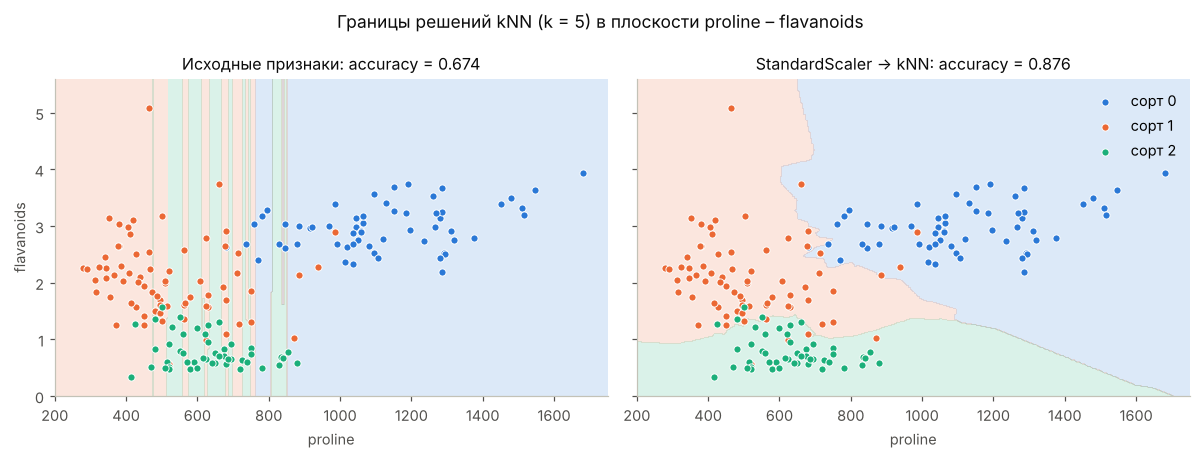

In [10]:
pair = [WINE_FEATURES.index("proline"), WINE_FEATURES.index("flavanoids")]
X_pair = X_wine[:, pair]
xx, yy = np.meshgrid(np.linspace(200, 1750, 350), np.linspace(0, 5.6, 350))
mesh = np.c_[xx.ravel(), yy.ravel()]

boundary_models = {
    "Исходные признаки": KNeighborsClassifier(),
    "StandardScaler → kNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (title, model) in zip(axes, boundary_models.items()):
    accuracy = cross_val_score(model, X_pair, y_wine, cv=CV).mean()
    regions = model.fit(X_pair, y_wine).predict(mesh).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=[BLUE, ORANGE, AQUA], alpha=0.16)
    for label, color in enumerate([BLUE, ORANGE, AQUA]):
        ax.scatter(*X_pair[y_wine == label].T, s=22, color=color, edgecolor="white",
                   linewidth=0.6, label=f"сорт {label}")
    ax.set_title(f"{title}: accuracy = {accuracy:.3f}")
    ax.set_xlabel("proline")
    ax.grid(False)
axes[0].set_ylabel("flavanoids")
axes[1].legend(loc="upper right")
fig.suptitle("Границы решений kNN (k = 5) в плоскости proline – flavanoids", color=INK)
plt.tight_layout()
plt.show()

В исходных единицах границы решений вертикальны: стандартное отклонение `proline` (314) в 315 раз больше, чем у `flavanoids` (1,0), и второй признак, хорошо отделяющий сорт 2, на расстояние практически не влияет. После стандартизации оба признака равноправны, и accuracy на кросс-валидации возрастает с 0,674 до 0,876.

## 5. Влияние масштабирования на разные классификаторы

Семь классификаторов с параметрами по умолчанию, четыре варианта первого шага конвейера и четыре набора данных; оценка - средняя accuracy на 5-fold стратифицированной кросс-валидации. Для логистической регрессии лимит итераций увеличен до 10 000, чтобы на немасштабированных данных оптимизация сходилась и сравнение отражало модель, а не остановку по лимиту.

In [11]:
CLASSIFIERS = {
    "kNN": KNeighborsClassifier(),
    "SVC (RBF)": SVC(),
    "LogisticRegression": LogisticRegression(max_iter=10_000),
    "MLP": MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE),
    "GaussianNB": GaussianNB(),
}
SCALERS = {
    "passthrough": "passthrough",
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

records = []
for data_name, (X, y) in DATASETS.items():
    for clf_name, clf in CLASSIFIERS.items():
        for scaler_name, scaler in SCALERS.items():
            scores = cross_val_score(Pipeline([("scaler", scaler), ("clf", clf)]), X, y, cv=CV, n_jobs=-1)
            records.append((data_name, clf_name, scaler_name, scores.mean()))

scaling = (pd.DataFrame(records, columns=["data", "classifier", "scaler", "accuracy"])
           .set_index(["data", "classifier", "scaler"])["accuracy"].unstack()[list(SCALERS)])
print(scaling.round(3).to_string())

scaler                            passthrough  StandardScaler  MinMaxScaler  RobustScaler
data          classifier                                                                 
breast_cancer DecisionTree              0.910           0.910         0.910         0.910
              GaussianNB                0.939           0.930         0.930         0.930
              LogisticRegression        0.954           0.974         0.965         0.979
              MLP                       0.931           0.977         0.974         0.972
              RandomForest              0.956           0.956         0.956         0.956
              SVC (RBF)                 0.914           0.977         0.975         0.974
              kNN                       0.935           0.963         0.963         0.960
digits        DecisionTree              0.855           0.854         0.855         0.856
              GaussianNB                0.845           0.780         0.818         0.835
          

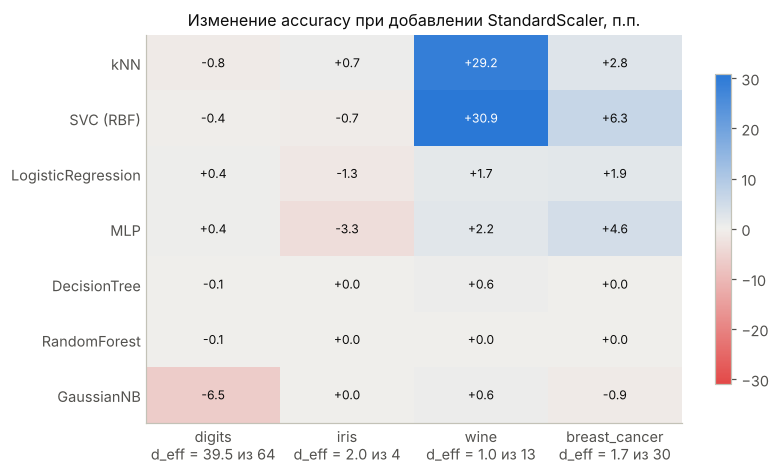

In [12]:
d_eff = {name: effective_dimension(X) for name, (X, _) in DATASETS.items()}
order = sorted(DATASETS, key=lambda name: d_eff[name] / DATASETS[name][0].shape[1], reverse=True)
gain = 100 * (scaling["StandardScaler"] - scaling["passthrough"]).unstack(0).loc[list(CLASSIFIERS), order]
limit = np.abs(gain.values).max()

fig, ax = plt.subplots(figsize=(7.6, 4.4))
image = ax.imshow(gain.values, cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
annotate_heatmap(ax, gain.values, "+.1f", dark_above=0.6 * limit)
ax.set_xticks(range(len(order)), [f"{name}\nd_eff = {d_eff[name]:.1f} из {DATASETS[name][0].shape[1]}"
                                  for name in order])
ax.set_yticks(range(len(gain)), gain.index)
ax.tick_params(length=0)
ax.set_title("Изменение accuracy при добавлении StandardScaler, п.п.")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

Столбцы упорядочены по убыванию доли эффективной размерности $d_{\text{eff}}/d$.

- **kNN и SVC** наиболее чувствительны к масштабу: на `wine` стандартизация повышает accuracy на 29,2 и 30,9 п.п., на `breast_cancer` на 2,8 и 6,3 п.п. Для логистической регрессии и MLP прирост меньше, от 1,7 до 4,6 п.п.
- **Деревья и случайный лес** инвариантны к масштабу. Расхождение 0,6 п.п. у дерева на `wine` соответствует одному объекту и вызвано выбором между равноценными разбиениями при численно различающихся значениях критерия.
- **Величина эффекта определяется данными.** На `wine` и `breast_cancer` расстояние определяется одним-двумя признаками из 13 и 30, и масштабирование даёт основной прирост. На `iris` и `digits` разбросы признаков сопоставимы, и масштабирование ничего не даёт; колебания на `iris` (0,7–3,3 п.п.) соответствуют 1–5 объектам из 150.
- **GaussianNB** теряет на `digits` 6,5 п.п.: сглаживание $\varepsilon$ вычисляется от максимальной дисперсии, и после стандартизации сглаживание признака $k$ относительно его дисперсии уменьшается в $\max_j \operatorname{Var}(x_j)/\operatorname{Var}(x_k)$ раз.
- Выбор между `StandardScaler`, `MinMaxScaler` и `RobustScaler` на `wine` и `breast_cancer` меняет результат не более чем на 1,5 п.п.; существенно само наличие масштабирования. Исключение составляет `digits`, где kNN с `RobustScaler` теряет 6,3 п.п.

Последний эффект объясняется эффективной размерностью после каждого преобразования.

In [13]:
X_digits = DATASETS["digits"][0]
for scaler_name, scaler in SCALERS.items():
    Z = X_digits if scaler_name == "passthrough" else clone(scaler).fit_transform(X_digits)
    print(f"digits, {scaler_name:15s} d_eff = {effective_dimension(Z):5.1f} из {X_digits.shape[1]}")

digits, passthrough     d_eff =  39.5 из 64
digits, StandardScaler  d_eff =  61.0 из 64
digits, MinMaxScaler    d_eff =  40.4 из 64
digits, RobustScaler    d_eff =  12.7 из 64


В `digits` все признаки измерены в одной шкале яркости, и их разброс сам несёт информацию. `RobustScaler` делит на межквартильный размах, который у пикселей, ненулевых лишь в части изображений, мал по сравнению с размахом значений; в результате расстояние не выравнивается, а концентрируется на немногих таких пикселях, и $d_{\text{eff}}$ падает с 39,5 до 12,7.

Масштаб признаков влияет и на сходимость оптимизации. Для логистической регрессии сравним число итераций L-BFGS до сходимости и поведение при лимите итераций по умолчанию (`max_iter=100`).

In [14]:
rows = []
for data_name in ("wine", "breast_cancer"):
    X, y = DATASETS[data_name]
    for scaler_name in ("passthrough", "StandardScaler"):
        pipeline = Pipeline([("scaler", SCALERS[scaler_name]), ("clf", LogisticRegression(max_iter=10_000))])
        converged = clone(pipeline).fit(X, y)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            clone(pipeline).set_params(clf__max_iter=100).fit(X, y)
        rows.append({
            "данные": data_name,
            "масштабирование": scaler_name,
            "итераций L-BFGS": int(converged[-1].n_iter_.max()),
            "сходимость при max_iter=100": not any(w.category is ConvergenceWarning for w in caught),
            "accuracy (CV)": round(scaling.loc[(data_name, "LogisticRegression"), scaler_name], 3),
        })
print(pd.DataFrame(rows).to_string(index=False))

       данные масштабирование  итераций L-BFGS  сходимость при max_iter=100  accuracy (CV)
         wine     passthrough             3019                        False          0.966
         wine  StandardScaler               15                         True          0.983
breast_cancer     passthrough             2539                        False          0.954
breast_cancer  StandardScaler               19                         True          0.974


На исходных признаках L-BFGS требуется 3019 и 2539 итераций против 15 и 19 после стандартизации, и при лимите по умолчанию оптимизация не сходится. Даже после сходимости accuracy ниже (0,966 против 0,983 и 0,954 против 0,974): штраф $\|w\|^2$ неодинаково ограничивает коэффициенты признаков разного масштаба.

## 6. Ошибки ручной предобработки

Без конвейера масштабирование и модель являются независимыми объектами, и согласованность их применения обеспечивается только дисциплиной кода. Рассмотрим три ошибки на `wine` и `breast_cancer` для kNN и SVC; во всех случаях обучающая часть составляет 70 % выборки.

**Ошибка 1. Масштабирование не применено при предсказании:** модель обучена на стандартизованных признаках, а на вход получает исходные.

In [15]:
SPLITS = {name: train_test_split(*DATASETS[name], test_size=0.3, stratify=DATASETS[name][1],
                                 random_state=RANDOM_STATE)
          for name in ("wine", "breast_cancer")}
MODELS = {"kNN": KNeighborsClassifier(), "SVC": SVC()}

fitted, rows = {}, []
for data_name, (X_tr, X_te, y_tr, y_te) in SPLITS.items():
    for model_name, model in MODELS.items():
        fitted[data_name, model_name] = make_pipeline(StandardScaler(), clone(model)).fit(X_tr, y_tr)
        raw_prediction = fitted[data_name, model_name][-1].predict(X_te)
        rows.append({
            "данные": data_name,
            "модель": model_name,
            "конвейер": fitted[data_name, model_name].score(X_te, y_te),
            "исходные признаки": accuracy_score(y_te, raw_prediction),
            "различных ответов": len(np.unique(raw_prediction)),
        })
print(pd.DataFrame(rows).round(3).to_string(index=False))

       данные модель  конвейер  исходные признаки  различных ответов
         wine    kNN     0.944              0.333                  1
         wine    SVC     0.981              0.389                  1
breast_cancer    kNN     0.959              0.374                  1
breast_cancer    SVC     0.977              0.374                  1


Модель выдаёт один и тот же ответ для всех объектов, и accuracy падает до доли этого класса. Стандартизованные обучающие объекты лежат в пределах нескольких единиц от нуля, а исходные значения отдельных признаков имеют порядок $10^2$–$10^3$, поэтому kNN для всех объектов находит одних и тех же соседей, а RBF-ядро обращается в ноль. Исключения при этом не возникает, поскольку число признаков совпадает. Конвейер принимает исходные признаки и масштабирует их сам, что исключает эту ошибку.

**Ошибка 2. Новые данные масштабируются собственными статистиками** (`fit_transform` вместо `transform`). На большой контрольной выборке её среднее и дисперсия близки к обучающим, и ошибка незаметна. При эксплуатации объекты поступают по одному или небольшими партиями; смоделируем это, разбивая контрольную часть на случайные партии размера $b$ (50 повторов на каждое $b$).

In [16]:
BATCH_SIZES = [1, 2, 3, 5, 10, 20, 50]
N_REPEATS = 50


def own_statistics_accuracy(model, X, y, batch_size, rng):
    order = rng.permutation(len(y))[: len(y) - len(y) % batch_size]
    batches = order.reshape(-1, batch_size)
    prediction = np.concatenate([model.predict(StandardScaler().fit_transform(X[b])) for b in batches])
    return accuracy_score(y[batches.ravel()], prediction)


batch_accuracy = {}
for (data_name, model_name), model in fitted.items():
    X_te, y_te = SPLITS[data_name][1], SPLITS[data_name][3]
    rng = np.random.RandomState(RANDOM_STATE)
    batch_accuracy[data_name, model_name] = [
        np.mean([own_statistics_accuracy(model[-1], X_te, y_te, b, rng) for _ in range(N_REPEATS)])
        for b in BATCH_SIZES
    ]
print(pd.DataFrame(batch_accuracy, index=pd.Index(BATCH_SIZES, name="b")).T.round(3).to_string())

b                     1      2      3      5      10     20     50
wine          kNN  0.333  0.756  0.804  0.882  0.932  0.945  0.960
              SVC  0.333  0.781  0.818  0.891  0.947  0.973  0.981
breast_cancer kNN  0.626  0.736  0.809  0.873  0.911  0.935  0.948
              SVC  0.626  0.728  0.803  0.876  0.919  0.946  0.961


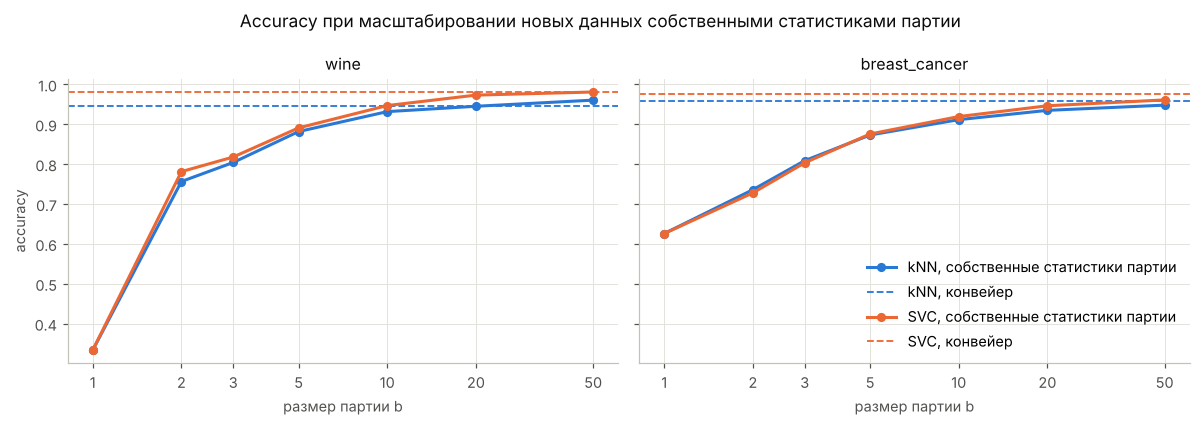

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, data_name in zip(axes, SPLITS):
    X_te, y_te = SPLITS[data_name][1], SPLITS[data_name][3]
    for model_name, color in zip(MODELS, [BLUE, ORANGE]):
        ax.plot(BATCH_SIZES, batch_accuracy[data_name, model_name], marker="o", ms=5, color=color,
                label=f"{model_name}, собственные статистики партии")
        ax.axhline(fitted[data_name, model_name].score(X_te, y_te), color=color, ls="--", lw=1.2,
                   label=f"{model_name}, конвейер")
    ax.set_xscale("log")
    ax.set_xticks(BATCH_SIZES, BATCH_SIZES)
    ax.minorticks_off()
    ax.set_xlabel("размер партии b")
    ax.set_title(data_name)
axes[0].set_ylabel("accuracy")
axes[1].legend(loc="lower right")
fig.suptitle("Accuracy при масштабировании новых данных собственными статистиками партии", color=INK)
plt.tight_layout()
plt.show()

При $b = 1$ стандартизация превращает объект в нулевой вектор, и модель выдаёт константу: accuracy 0,333 на `wine` и 0,626 на `breast_cancer` равна доле одного класса. При $b = 5$ потеря составляет 6–10 п.п., при $b = 10$ 1–6 п.п., при $b = 50$ не более 1,6 п.п. Проверка на полной контрольной выборке эту ошибку не выявляет.

**Ошибка 3. Масштабирование до разбиения на блоки кросс-валидации:** параметры масштабирования оцениваются по всей выборке, включая контрольные блоки. Сравним такую оценку с конвейером на 50 различных разбиениях.

In [18]:
rows = []
for data_name in ("wine", "breast_cancer"):
    X, y = DATASETS[data_name]
    X_scaled_globally = StandardScaler().fit_transform(X)
    for model_name, model in MODELS.items():
        bias = []
        for seed in range(50):
            cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
            outside = cross_val_score(model, X_scaled_globally, y, cv=cv).mean()
            inside = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv).mean()
            bias.append(100 * (outside - inside))
        rows.append({
            "данные": data_name,
            "модель": model_name,
            "среднее смещение, п.п.": np.mean(bias),
            "std, п.п.": np.std(bias),
            "доля завышенных оценок": np.mean(np.array(bias) > 0),
            "доля заниженных оценок": np.mean(np.array(bias) < 0),
        })
print(pd.DataFrame(rows).round(2).to_string(index=False))

       данные модель  среднее смещение, п.п.  std, п.п.  доля завышенных оценок  доля заниженных оценок
         wine    kNN                    0.04       0.39                    0.28                    0.22
         wine    SVC                   -0.03       0.24                    0.06                    0.12
breast_cancer    kNN                    0.02       0.17                    0.36                    0.22
breast_cancer    SVC                    0.02       0.10                    0.22                    0.10


Систематического смещения нет: средние значения от −0,03 до +0,04 п.п. при стандартном отклонении 0,1–0,4 п.п., завышенные и заниженные оценки встречаются с сопоставимой частотой. Масштабирование не использует метки, а статистики четырёх пятых выборки мало отличаются от статистик всей выборки. Следовательно, для масштабирования независимых одинаково распределённых данных основной риск ручной предобработки связан не с оценкой качества, а с применением модели (ошибки 1 и 2). Для шагов, использующих метки, например отбора признаков, выполнение до разбиения приводит к сильному завышению оценки; конвейер исключает и эту ошибку, поскольку все его шаги настраиваются внутри обучающего блока.

## 7. Совместный подбор параметров масштабирования и классификатора

Конвейер является обычным estimator, поэтому `GridSearchCV` перебирает параметры всех его шагов, а масштабирование настраивается заново на каждом обучающем блоке. Сначала сравним сетку $C \times \gamma$ для SVC на `wine` в стандартизованных и исходных признаках.

In [19]:
C_GRID = np.logspace(-2, 4, 7)
GAMMA_GRID = np.logspace(-8, 1, 10)

svc_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("clf", SVC())]),
    {"scaler": [StandardScaler(), "passthrough"], "clf__C": C_GRID, "clf__gamma": GAMMA_GRID},
    cv=CV, n_jobs=-1,
).fit(X_wine, y_wine)

svc_results = pd.DataFrame(svc_search.cv_results_)
svc_results["scaler"] = svc_results["param_scaler"].map(step_name)
surfaces = {
    scaler: group.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_score")
    for scaler, group in svc_results.groupby("scaler")
}
for scaler, surface in surfaces.items():
    i, j = np.unravel_index(surface.values.argmax(), surface.shape)
    print(f"{scaler:15s} максимум {surface.values.max():.3f} при C = {surface.index[i]:g}, "
          f"gamma = {surface.columns[j]:g}; доля сетки с accuracy ≥ 0.95: {np.mean(surface.values >= 0.95):.0%}")

StandardScaler  максимум 0.989 при C = 1, gamma = 0.01; доля сетки с accuracy ≥ 0.95: 30%
passthrough     максимум 0.944 при C = 10000, gamma = 1e-06; доля сетки с accuracy ≥ 0.95: 0%


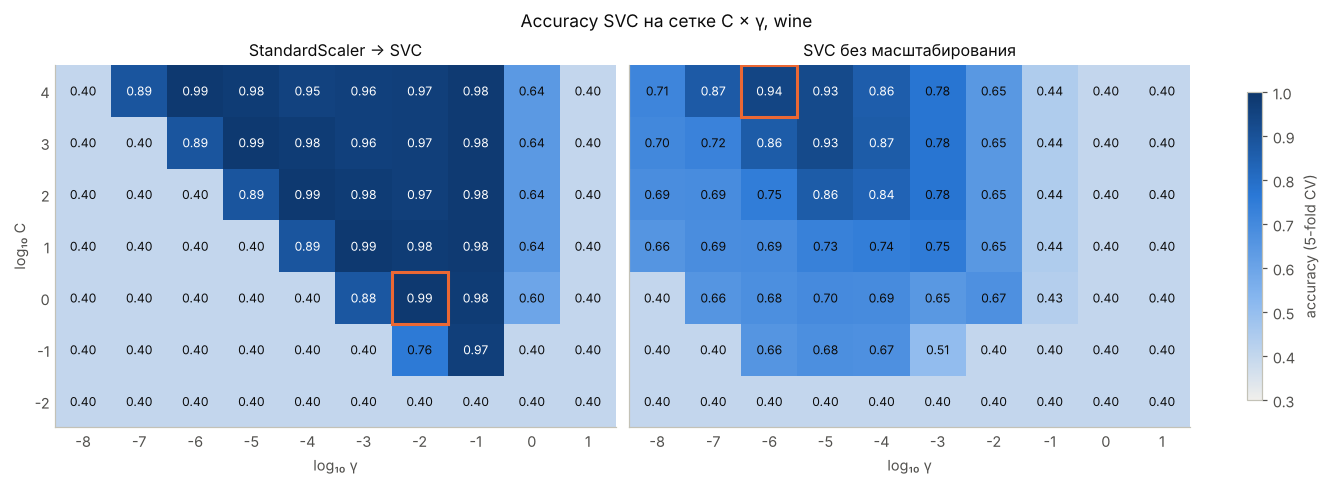

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True, layout="constrained")
for ax, scaler in zip(axes, ["StandardScaler", "passthrough"]):
    surface = surfaces[scaler]
    image = ax.imshow(surface.values, cmap=SEQUENTIAL, vmin=0.3, vmax=1.0, aspect="auto", origin="lower")
    annotate_heatmap(ax, surface.values, ".2f", dark_above=0.8)
    i, j = np.unravel_index(surface.values.argmax(), surface.shape)
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANGE, linewidth=2))
    ax.set_xticks(range(len(GAMMA_GRID)), [f"{np.log10(g):.0f}" for g in GAMMA_GRID])
    ax.set_yticks(range(len(C_GRID)), [f"{np.log10(c):.0f}" for c in C_GRID])
    ax.set_xlabel("log₁₀ γ")
    ax.tick_params(length=0)
    ax.set_title("StandardScaler → SVC" if scaler == "StandardScaler" else "SVC без масштабирования")
axes[0].set_ylabel("log₁₀ C")
fig.colorbar(image, ax=axes, shrink=0.85, label="accuracy (5-fold CV)")
fig.suptitle("Accuracy SVC на сетке C × γ, wine", color=INK)
plt.show()

Со стандартизацией максимум 0,989 достигается при $C = 1$, $\gamma = 0{,}01$, и 30 % сетки дают accuracy не ниже 0,95; область хороших значений образует широкую диагональ, вдоль которой рост $C$ компенсируется уменьшением $\gamma$. Без масштабирования ни одна конфигурация не достигает 0,95, а лучшая (0,944) лежит на границе сетки при $C = 10^4$, $\gamma = 10^{-6}$. Оптимальное $\gamma$ смещено на четыре порядка, так как средний квадрат расстояния определяется `proline` и составляет $2\sum_j \operatorname{Var}(x_j) \approx 2\cdot10^5$ против 26 после стандартизации. При $\gamma \geq 0{,}1$, где в стандартизованном пространстве находится часть лучших конфигураций, классификатор на исходных признаках вырождается в константу (0,40 — доля крупнейшего сорта). Подбор гиперпараметров частично компенсирует отсутствие масштабирования, но не заменяет его.

Далее масштабирование становится полноценным гиперпараметром: в сетку входят четыре варианта первого шага и три классификатора со своими параметрами, а сам классификатор задаётся как значение параметра `clf`. Значение `best_score_` является максимумом по всем конфигурациям и потому смещено вверх, поэтому качество процедуры подбора оценивается вложенной кросс-валидацией: внутренний цикл выбирает конфигурацию, внешний оценивает её на блоках, не участвовавших в выборе.

Сетка $C$ для логистической регрессии ограничена значением 10: при больших $C$ на исходных признаках `breast_cancer` L-BFGS не сходится и за 10 000 итераций, и результат перестаёт быть воспроизводимым между версиями библиотеки.

In [21]:
SCALER_OPTIONS = [StandardScaler(), MinMaxScaler(), RobustScaler(), "passthrough"]
PARAM_GRID = [
    {"scaler": SCALER_OPTIONS, "clf": [SVC()],
     "clf__C": np.logspace(-1, 3, 5), "clf__gamma": np.logspace(-4, 0, 5)},
    {"scaler": SCALER_OPTIONS, "clf": [KNeighborsClassifier()],
     "clf__n_neighbors": [1, 3, 5, 9, 15, 25], "clf__weights": ["uniform", "distance"]},
    {"scaler": SCALER_OPTIONS, "clf": [LogisticRegression(max_iter=10_000)],
     "clf__C": np.logspace(-2, 1, 4)},
]
INNER = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
OUTER = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


def make_search():
    return GridSearchCV(Pipeline([("scaler", StandardScaler()), ("clf", SVC())]),
                        PARAM_GRID, cv=INNER, n_jobs=-1)


def describe(params):
    clf_params = ", ".join(f"{key.removeprefix('clf__')}={value:g}" if isinstance(value, float)
                           else f"{key.removeprefix('clf__')}={value}"
                           for key, value in params.items() if key.startswith("clf__"))
    return f"{step_name(params['scaler'])} → {step_name(params['clf'])} ({clf_params})"


print("конфигураций в сетке:", len(ParameterGrid(PARAM_GRID)))

searches, summary = {}, []
for data_name in ("wine", "breast_cancer"):
    X, y = DATASETS[data_name]
    nested = cross_validate(make_search(), X, y, cv=OUTER, return_estimator=True)
    searches[data_name] = make_search().fit(X, y)
    summary.append({
        "данные": data_name,
        "best_score_": round(searches[data_name].best_score_, 3),
        "вложенная CV": f"{nested['test_score'].mean():.3f} ± {nested['test_score'].std():.3f}",
        "выбранная конфигурация": describe(searches[data_name].best_params_),
    })
    print(f"\n{data_name}: конфигурации, выбранные во внешних блоках")
    for fold, (estimator, score) in enumerate(zip(nested["estimator"], nested["test_score"]), start=1):
        print(f"  блок {fold}: {describe(estimator.best_params_):60s} accuracy = {score:.3f}")

print()
print(pd.DataFrame(summary).to_string(index=False))

конфигураций в сетке: 164



wine: конфигурации, выбранные во внешних блоках
  блок 1: MinMaxScaler → LogisticRegression (C=1)                      accuracy = 0.972
  блок 2: StandardScaler → LogisticRegression (C=10)                   accuracy = 0.972
  блок 3: StandardScaler → SVC (C=1, gamma=0.1)                        accuracy = 0.972
  блок 4: StandardScaler → SVC (C=1, gamma=0.01)                       accuracy = 0.971
  блок 5: StandardScaler → LogisticRegression (C=0.1)                  accuracy = 1.000



breast_cancer: конфигурации, выбранные во внешних блоках
  блок 1: RobustScaler → LogisticRegression (C=1)                      accuracy = 0.965
  блок 2: StandardScaler → SVC (C=10, gamma=0.01)                      accuracy = 0.991
  блок 3: MinMaxScaler → SVC (C=1000, gamma=0.01)                      accuracy = 0.974
  блок 4: StandardScaler → SVC (C=10, gamma=0.01)                      accuracy = 0.991
  блок 5: StandardScaler → SVC (C=10, gamma=0.01)                      accuracy = 0.973

       данные  best_score_  вложенная CV                  выбранная конфигурация
         wine        0.994 0.978 ± 0.011  StandardScaler → SVC (C=1, gamma=0.01)
breast_cancer        0.982 0.979 ± 0.011 StandardScaler → SVC (C=10, gamma=0.01)


Вариант без масштабирования не выбран ни в одном внешнем блоке. Выбор между тремя масштабирующими преобразованиями, а также между SVC и логистической регрессией меняется от блока к блоку, поскольку их качество различается в пределах шума. Значение `best_score_` завышает качество процедуры подбора: на `wine` 0,994 против 0,978 по вложенной кросс-валидации, на `breast_cancer` 0,982 против 0,979.

In [22]:
for data_name, search in searches.items():
    results = pd.DataFrame(search.cv_results_)
    results["scaler"] = results["param_scaler"].map(step_name)
    results["classifier"] = results["param_clf"].map(step_name)
    best = results.pivot_table(index="classifier", columns="scaler", values="mean_test_score", aggfunc="max")
    print(f"{data_name}: лучшая accuracy по сочетаниям классификатора и масштабирования")
    print(best[["StandardScaler", "MinMaxScaler", "RobustScaler", "passthrough"]].round(3).to_string(), "\n")

wine: лучшая accuracy по сочетаниям классификатора и масштабирования
scaler                StandardScaler  MinMaxScaler  RobustScaler  passthrough
classifier                                                                   
KNeighborsClassifier           0.972         0.972         0.972        0.753
LogisticRegression             0.994         0.989         0.983        0.961
SVC                            0.994         0.989         0.983        0.865 

breast_cancer: лучшая accuracy по сочетаниям классификатора и масштабирования
scaler                StandardScaler  MinMaxScaler  RobustScaler  passthrough
classifier                                                                   
KNeighborsClassifier           0.970         0.974         0.965        0.940
LogisticRegression             0.979         0.979         0.977        0.953
SVC                            0.982         0.981         0.981        0.949 



Даже после подбора гиперпараметров конфигурации без масштабирования уступают: на `wine` kNN достигает лишь 0,753 и SVC 0,865 против 0,972 и 0,994 со стандартизацией, на `breast_cancer` отставание составляет 2,6–3,4 п.п. для всех трёх моделей. Различия между тремя масштабирующими преобразованиями не превышают 1,1 п.п.

## 8. Выводы

1. `Pipeline` последовательно настраивает преобразования на обучающих данных и применяет сохранённые параметры к новым. Собственная реализация из двух циклов совпадает с библиотечной во всех блоках кросс-валидации; библиотечный класс добавляет доступ к параметрам шагов по именам `<шаг>__<параметр>`, замену шагов и срезы.
2. Масштабирование необходимо методам, основанным на расстояниях, ядрах и градиентной оптимизации: на `wine` оно повышает accuracy kNN и SVC на 29–31 п.п., логистической регрессии и MLP примерно на 2 п.п. Деревья решений и случайный лес к масштабу инвариантны, GaussianNB инвариантен с точностью до `var_smoothing`.
3. Величина эффекта определяется неоднородностью масштабов, которую характеризует эффективная размерность $d_{\text{eff}}$: при $d_{\text{eff}} = 1{,}0$ из 13 (`wine`) и 1,7 из 30 (`breast_cancer`) прирост велик, при сопоставимых разбросах (`iris`, `digits`) отсутствует. Если признаки измерены в одной шкале, масштабирование может ухудшить качество: на `digits` `RobustScaler` снижает $d_{\text{eff}}$ с 39,5 до 12,7, и kNN теряет 6,3 п.п.
4. Масштаб определяет обусловленность оптимизации: логистической регрессии на исходных признаках требуется в 130–200 раз больше итераций, а после сходимости её accuracy ниже на 1,7–1,9 п.п. из-за неодинакового действия L2-штрафа.
5. Конвейер исключает ошибки применения модели. Без масштабирования при предсказании модель выдаёт константу; масштабирование новых данных их собственными статистиками снижает accuracy до доли одного класса при поступлении объектов по одному и на 6–10 п.п. при партиях по пять. Масштабирование до разбиения на блоки кросс-валидации на рассмотренных данных измеримого смещения не даёт (не более 0,04 п.п. по модулю).
6. Конвейер позволяет подбирать параметры масштабирования и классификатора совместно, рассматривая сам масштабатор как гиперпараметр. Вариант без масштабирования не выбирается ни в одном блоке, а оптимальное $\gamma$ SVC в исходных единицах смещается на четыре порядка и не достигает качества стандартизованной модели. Качество процедуры подбора следует оценивать вложенной кросс-валидацией: `best_score_` завышает его на величину до 1,6 п.п.